# QUANT Interval-Selection Experiment Analysis

This notebook compares saved results from different QUANT interval configurations. **It does not run or retrain anything**; it reads the CSVs written by `run.py`.

**How the numbers are built**

1. Only runs with `status == "ok"` are used, and only resamples that succeeded for **every** configuration (so every comparison is paired on identical train/test splits).
2. For each dataset × configuration × classifier, accuracy, feature count and timings are **averaged over the resamples** (timings can switch to the median with `TIME_AGG`).
3. Every configuration is compared to the baseline *within the same dataset*, giving per-dataset accuracy differences, relative error reduction, and feature/time reductions (positive = better than baseline).
4. Datasets are split into size groups (equal-count percentile bins) so you can see whether a configuration helps more on small or large datasets.

> Use a separate results CSV per configuration. The `run.py` resume key is dataset + resample + classifier, so sharing one output file across configurations can cause runs to be skipped.

## 1. Configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
from scipy import stats

# --- Inputs -----------------------------------------------------------------
RESULTS_DIR = Path("../results")

# CSV filename stem -> display label. Each stem must have <RESULTS_DIR>/<stem>.csv
CONFIG_LABELS = {
    "depths_0_6_baseline": "Baseline (depths 0–6)",
    "even_depths": "Even depths (0, 2, 4, 6)",
    "alternating_depths": "Alternating normal/shift",
}
BASELINE = "Baseline (depths 0–6)"   # must be one of the labels above

CLASSIFIERS = None                    # e.g. ["extratrees"]; None = all found in the CSVs

# --- Aggregation / statistics -----------------------------------------------
TIME_AGG = "mean"                     # how timings are combined over resamples: "mean" or "median"
TIE_TOL = 1e-12                       # |accuracy difference| below this counts as a tie
N_BOOTSTRAP = 5000                    # bootstrap resamples for the mean-difference confidence interval
ERROR_EPS = 0.001                     # pseudo-error added to BOTH errors in the smoothed error ratio (0.001 = 0.1 pp)
                                      # ideally ~0.5 / n_test; try 0.0005 and 0.002 to check the conclusions do not change
SEED = 0

# --- Dataset-size groups ----------------------------------------------------
N_SIZE_GROUPS = 5                     # equal-count percentile bins (5 = quintiles)
# Optional CSV with one row per dataset: dataset, n_train, series_length[, n_channels]
# (or a single precomputed `size` column). If None, the notebook looks for such
# columns in the results CSVs, and otherwise falls back to a runtime-based proxy.
SIZE_METADATA_CSV = None              # e.g. Path("../dataset_metadata.csv")

print("Results directory:", RESULTS_DIR.resolve())

Results directory: C:\Users\davyt\quant-reproduction\results


## 2. Load and validate

Missing or malformed files are reported rather than silently skipped, and the notebook stops if the baseline is not available.

In [2]:
REQUIRED = {
    "dataset", "resample", "classifier", "accuracy", "status", "n_features",
    "time_transform_train", "time_fit", "time_transform_test", "time_predict",
}
NUMERIC = [
    "accuracy", "balanced_accuracy", "n_features",
    "time_transform_train", "time_fit", "time_transform_test", "time_predict",
]

frames, load_issues = [], []
for stem, label in CONFIG_LABELS.items():
    path = RESULTS_DIR / f"{stem}.csv"
    try:
        frame = pd.read_csv(path)
    except Exception as exc:
        load_issues.append({"file": str(path), "issue": f"Could not read: {exc}"})
        continue
    missing = sorted(REQUIRED - set(frame.columns))
    if missing:
        load_issues.append({"file": str(path), "issue": "Missing columns: " + ", ".join(missing)})
        continue
    frame["configuration"] = label
    for col in NUMERIC:
        frame[col] = pd.to_numeric(frame[col], errors="coerce") if col in frame else np.nan
    frame["resample"] = pd.to_numeric(frame["resample"], errors="coerce")
    frame["status"] = frame["status"].fillna("").astype(str)
    frames.append(frame)

if load_issues:
    display(pd.DataFrame(load_issues))
if not frames:
    raise FileNotFoundError("No usable result CSVs found. Check RESULTS_DIR and CONFIG_LABELS.")

results = pd.concat(frames, ignore_index=True, sort=False)
if BASELINE not in set(results["configuration"]):
    raise ValueError(f"Baseline '{BASELINE}' was not loaded. Loaded: {sorted(results['configuration'].unique())}")
if CLASSIFIERS is not None:
    results = results[results["classifier"].isin(CLASSIFIERS)].copy()

# Duplicated runs would double-count a resample, so keep the first and say so.
run_key = ["configuration", "dataset", "classifier", "resample"]
n_dup = int(results.duplicated(run_key).sum())
if n_dup:
    print(f"WARNING: dropped {n_dup} duplicated runs (same configuration/dataset/classifier/resample).")
    results = results.drop_duplicates(run_key, keep="first")

results["is_success"] = results["status"].str.lower().eq("ok") & results["accuracy"].notna()

print(f"Loaded {len(results):,} runs from {len(frames)} file(s); "
      f"{int(results['is_success'].sum()):,} successful.")
display(
    results.groupby(["configuration", "classifier", "status"]).size()
    .rename("runs").reset_index()
)

Loaded 2,130 runs from 3 file(s); 2,130 successful.


,configuration,classifier,status,runs
0,Alternating normal/shift,extratrees,ok,710
1,Baseline (depths 0–6),extratrees,ok,710
2,"Even depths (0, 2, 4, 6)",extratrees,ok,710


## 3. Paired runs and per-dataset averages

A resample is kept only if the same dataset/classifier/resample succeeded in **all** configurations, so every configuration is averaged over the same splits. The table `table` has one row per dataset × configuration × classifier and is used by everything below.

In [3]:
ok = results.loc[results["is_success"]].copy()
ok["time_train_total"] = ok["time_transform_train"] + ok["time_fit"]
ok["time_test_total"] = ok["time_transform_test"] + ok["time_predict"]

# Keep only resamples that succeeded in every configuration.
all_configs = sorted(ok["configuration"].unique())
pair_key = ["dataset", "classifier", "resample"]
n_cfg = ok.groupby(pair_key)["configuration"].transform("nunique")
paired = ok.loc[n_cfg == len(all_configs)].copy()
print(f"Configurations: {all_configs}")
print(f"Successful runs: {len(ok):,} -> kept {len(paired):,} runs in complete resample sets "
      f"({len(ok) - len(paired):,} dropped).")

TIME_COLS = ["time_transform_train", "time_fit", "time_transform_test", "time_predict",
             "time_train_total", "time_test_total"]
agg_spec = {
    "accuracy": ("accuracy", "mean"),
    "balanced_accuracy": ("balanced_accuracy", "mean"),
    "n_features": ("n_features", "mean"),
    "n_resamples": ("resample", "nunique"),
}
agg_spec.update({c: (c, TIME_AGG) for c in TIME_COLS})

table = (
    paired.groupby(["dataset", "classifier", "configuration"], as_index=False)
    .agg(**agg_spec)
)
table["error"] = 1 - table["accuracy"]

# Coverage check: every dataset should appear in every configuration with the same resample count.
cov = table.groupby(["classifier", "configuration"]).agg(
    datasets=("dataset", "nunique"),
    resamples_min=("n_resamples", "min"),
    resamples_median=("n_resamples", "median"),
    resamples_max=("n_resamples", "max"),
)
display(cov)
print(f"{table['dataset'].nunique()} datasets in the analysis table.")

Configurations: ['Alternating normal/shift', 'Baseline (depths 0–6)', 'Even depths (0, 2, 4, 6)']
Successful runs: 2,130 -> kept 2,130 runs in complete resample sets (0 dropped).


datasets  resamples_min  \
classifier configuration                                       
extratrees Alternating normal/shift       142              5   
           Baseline (depths 0–6)          142              5   
           Even depths (0, 2, 4, 6)       142              5   

                                     resamples_median  resamples_max  
classifier configuration                                              
extratrees Alternating normal/shift               5.0              5  
           Baseline (depths 0–6)                  5.0              5  
           Even depths (0, 2, 4, 6)               5.0              5

142 datasets in the analysis table.


## 4. Dataset-size groups

QUANT's cost scales with the number of training cases × series length × channels, so that is the preferred size measure. The notebook uses, in order:

1. `SIZE_METADATA_CSV` (or columns in the results CSVs) with `n_train` and `series_length` (and optionally `n_channels`);
2. a single `size` column, if present;
3. otherwise a **runtime proxy**: the geometric mean of `time_transform_train` across configurations. This is a reasonable stand-in for data volume, but it is measured, so noisy timings can nudge a dataset into a neighbouring group. Use real metadata for anything you plan to publish.

Groups are equal-count percentile bins (`N_SIZE_GROUPS`), so each group has roughly the same number of datasets.

In [4]:
SIZE_ALIASES = {
    "n_train": ["n_train", "n_train_cases", "n_cases_train", "train_size"],
    "length": ["series_length", "n_timepoints", "n_timesteps", "length"],
    "channels": ["n_channels", "n_dimensions", "n_dims"],
    "size": ["size", "dataset_size"],
}

def find_col(df, key):
    return next((c for c in SIZE_ALIASES[key] if c in df.columns), None)

def size_from_frame(df):
    # Return (Series indexed by dataset, description) or None if no usable columns.
    per_dataset = df.groupby("dataset").first()
    n_train, length, chans = (find_col(per_dataset, k) for k in ("n_train", "length", "channels"))
    if n_train and length:
        size = per_dataset[n_train] * per_dataset[length]
        if chans:
            size = size * per_dataset[chans].fillna(1)
        return size, "n_train × series_length" + (" × n_channels" if chans else "")
    size_col = find_col(per_dataset, "size")
    if size_col:
        return per_dataset[size_col], size_col
    return None

size_info = None
if SIZE_METADATA_CSV is not None:
    size_info = size_from_frame(pd.read_csv(SIZE_METADATA_CSV))
    if size_info is None:
        raise ValueError("SIZE_METADATA_CSV needs n_train + series_length columns, or a `size` column.")
if size_info is None:
    size_info = size_from_frame(results)

if size_info is not None:
    dataset_size, SIZE_DESC = size_info
    dataset_size = dataset_size.reindex(table["dataset"].unique())
    if dataset_size.isna().any():
        raise ValueError(f"No size for datasets: {list(dataset_size.index[dataset_size.isna()])[:10]}")
else:
    SIZE_DESC = "runtime proxy (geometric mean of training-transform time, s)"
    dataset_size = (
        table.groupby("dataset")["time_transform_train"]
        .apply(lambda s: float(np.exp(np.log(s.clip(lower=1e-9)).mean())))
    )
    print("NOTE: no dataset-size metadata found, using a runtime proxy for size groups.")

dataset_size = dataset_size.astype(float).sort_values()
# Rank first so ties can't collapse bins; groups end up equal-sized (±1 dataset).
bin_id = pd.qcut(dataset_size.rank(method="first"), N_SIZE_GROUPS, labels=False)

group_label = {}
for g in range(N_SIZE_GROUPS):
    members = dataset_size[bin_id == g]
    lo_pct, hi_pct = round(100 * g / N_SIZE_GROUPS), round(100 * (g + 1) / N_SIZE_GROUPS)
    group_label[g] = f"G{g + 1}: {lo_pct}–{hi_pct}th pct  (size {members.min():.3g}–{members.max():.3g}, n={len(members)})"

GROUP_ORDER = [group_label[g] for g in range(N_SIZE_GROUPS)]
dataset_group = bin_id.map(group_label)
table["size_group"] = pd.Categorical(table["dataset"].map(dataset_group), categories=GROUP_ORDER, ordered=True)

print("Size measure:", SIZE_DESC)
display(dataset_group.value_counts().reindex(GROUP_ORDER).rename("datasets").rename_axis("size group").to_frame())

NOTE: no dataset-size metadata found, using a runtime proxy for size groups.
Size measure: runtime proxy (geometric mean of training-transform time, s)


,datasets
size group,
"G1: 0–20th pct (size 0.0142–0.153, n=29)",29
"G2: 20–40th pct (size 0.16–0.219, n=28)",28
"G3: 40–60th pct (size 0.223–0.349, n=28)",28
"G4: 60–80th pct (size 0.35–0.539, n=28)",28
"G5: 80–100th pct (size 0.582–3.07, n=29)",29


## 5. Per-dataset comparison with the baseline

For each non-baseline configuration and dataset (all values positive = better than baseline unless noted):

- **Accuracy difference** (percentage points): $\Delta A = A_{\text{new}} - A_{\text{baseline}}$
- **Relative error reduction** (%): $\dfrac{E_{\text{baseline}} - E_{\text{new}}}{E_{\text{baseline}}}$, where $E = 1 - A$. This is **undefined when the baseline error is 0** (a perfect baseline), so those datasets are left out of this one metric (reported below) instead of producing `-inf`/`NaN`.
- **Smoothed error ratio**: $\\dfrac{E_{\\text{new}} + \\varepsilon}{E_{\\text{baseline}} + \\varepsilon}$ with a small pseudo-error $\\varepsilon$ (`ERROR_EPS`) added to both errors, averaged on the log scale (geometric mean). Unlike relative error reduction it is defined for perfect baselines and cannot be dominated by one or two test-case errors on a near-perfect dataset. 1.0 = no change, 1.2 = 20% more error.
- **Feature, training-time and test-time reduction** (%): $\dfrac{X_{\text{baseline}} - X_{\text{new}}}{X_{\text{baseline}}}$. Training time is `time_transform_train + time_fit`; test time is `time_transform_test + time_predict`.

In [5]:
BASE_COLS = ["accuracy", "error", "n_features", "time_train_total", "time_test_total"]

base = (
    table.loc[table["configuration"] == BASELINE]
    .set_index(["dataset", "classifier"])[BASE_COLS]
    .add_prefix("base_")
)
cmp = table.loc[table["configuration"] != BASELINE].join(base, on=["dataset", "classifier"])
cmp = cmp.dropna(subset=["base_accuracy"]).copy()

def pct_reduction(new, old):
    return 100 * (old - new) / old.where(old > 0)      # NaN where the baseline value is 0

cmp["acc_diff_pp"] = 100 * (cmp["accuracy"] - cmp["base_accuracy"])
cmp["error_reduction_pct"] = pct_reduction(cmp["error"], cmp["base_error"])
# Smoothed error ratio: the pseudo-error ERROR_EPS stops one or two test-case errors on a near-perfect
# baseline from producing a huge ratio. log2 makes "doubled" (+1) and "halved" (-1) symmetric.
cmp["log2_error_ratio"] = np.log2((cmp["error"] + ERROR_EPS) / (cmp["base_error"] + ERROR_EPS))
cmp["feature_reduction_pct"] = pct_reduction(cmp["n_features"], cmp["base_n_features"])
cmp["train_time_reduction_pct"] = pct_reduction(cmp["time_train_total"], cmp["base_time_train_total"])
cmp["test_time_reduction_pct"] = pct_reduction(cmp["time_test_total"], cmp["base_time_test_total"])

excluded = (
    cmp.assign(perfect_baseline=cmp["base_error"] <= 0)
    .groupby(["classifier", "configuration"])["perfect_baseline"].sum()
    .rename("datasets excluded from error reduction (baseline accuracy = 100%)")
)
display(excluded.to_frame())

COMPARE_CONFIGS = sorted(cmp["configuration"].unique())
palette = plt.get_cmap("tab10")
CONFIG_COLORS = {BASELINE: "#7f7f7f"}
CONFIG_COLORS.update({c: palette(i) for i, c in enumerate(COMPARE_CONFIGS)})
classifiers = sorted(table["classifier"].unique())

datasets excluded from error reduction (baseline accuracy = 100%)
classifier configuration                                                                              
extratrees Alternating normal/shift                                                  8                
           Even depths (0, 2, 4, 6)                                                  8

## 6. Summary statistics

Each row summarises one configuration against the baseline across datasets. Besides means and medians it reports:

- **improved / tied / declined**: datasets where the (averaged) accuracy went up, stayed within `TIE_TOL`, or went down;
- **95% CI**: bootstrap confidence interval for the mean accuracy difference (resampling datasets);
- **Wilcoxon p**: paired two-sided signed-rank test on the per-dataset accuracy differences (ties dropped). With several configurations and size groups you are making many comparisons, so treat isolated small p-values with caution and prefer the CI and the effect size.

In [6]:
rng = np.random.default_rng(SEED)

def bootstrap_ci(values, n_boot=N_BOOTSTRAP, alpha=0.05):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return np.nan, np.nan
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[idx].mean(axis=1)
    return tuple(np.quantile(means, [alpha / 2, 1 - alpha / 2]))

def wilcoxon_p(diffs):
    nonzero = diffs[np.abs(diffs) > TIE_TOL]
    if len(nonzero) < 6:                      # too few non-tied datasets for a meaningful test
        return np.nan
    return stats.wilcoxon(nonzero).pvalue

def summarise(frame, group_cols):
    rows = []
    for keys, g in frame.groupby(group_cols, observed=True):
        keys = keys if isinstance(keys, tuple) else (keys,)
        d = g["acc_diff_pp"].to_numpy()
        diff_frac = d / 100
        ci_lo, ci_hi = bootstrap_ci(d)
        rows.append({
            **dict(zip(group_cols, keys)),
            "datasets": len(g),
            "acc diff mean (pp)": d.mean(),
            "95% CI": f"[{ci_lo:.2f}, {ci_hi:.2f}]",
            "acc diff median (pp)": np.median(d),
            "improved": int((diff_frac > TIE_TOL).sum()),
            "tied": int((np.abs(diff_frac) <= TIE_TOL).sum()),
            "declined": int((diff_frac < -TIE_TOL).sum()),
            "Wilcoxon p": wilcoxon_p(diff_frac),
            "error red. mean (%)": g["error_reduction_pct"].mean(),
            "error red. median (%)": g["error_reduction_pct"].median(),
            "error red. n": int(g["error_reduction_pct"].notna().sum()),
            "smoothed error ratio (geo. mean)": 2 ** g["log2_error_ratio"].mean(),
            "feature red. mean (%)": g["feature_reduction_pct"].mean(),
            "train time red. mean (%)": g["train_time_reduction_pct"].mean(),
            "train time red. median (%)": g["train_time_reduction_pct"].median(),
            "test time red. mean (%)": g["test_time_reduction_pct"].mean(),
            "test time red. median (%)": g["test_time_reduction_pct"].median(),
        })
    return pd.DataFrame(rows)

def show(summary):
    pd.set_option("display.width", 250, "display.max_columns", None)
    display(
        summary.style.format(
            {c: "{:.2f}" for c in summary.columns if c.endswith(("(pp)", "(%)"))} | {"Wilcoxon p": "{:.4f}"},
            na_rep="–",
        ).hide(axis="index")
    )

### 6a. Overall (all datasets)

In [7]:
overall = summarise(cmp, ["classifier", "configuration"])
show(overall)

classifier,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,Alternating normal/shift,142,-0.28,"[-0.41, -0.14]",-0.21,32,11,99,0.0000,-17.18,-2.15,134,1.037920,46.18,15.42,19.52,24.36,31.18
extratrees,"Even depths (0, 2, 4, 6)",142,-0.29,"[-0.43, -0.16]",-0.11,40,14,88,0.0001,-16.19,-1.33,134,1.033402,44.15,4.44,13.46,11.20,14.97


### 6b. By dataset-size group

In [8]:
by_size = summarise(cmp, ["classifier", "size_group", "configuration"])
show(by_size)

classifier,size_group,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,"G1: 0–20th pct (size 0.0142–0.153, n=29)",Alternating normal/shift,29,-0.35,"[-0.57, -0.16]",-0.18,7,2,20,0.0014,-4.94,-3.17,28,1.042228,42.86,-4.22,7.82,12.97,18.76
extratrees,"G1: 0–20th pct (size 0.0142–0.153, n=29)","Even depths (0, 2, 4, 6)",29,-0.45,"[-0.79, -0.17]",-0.12,8,3,18,0.0079,-9.87,-2.86,28,1.063009,45.96,-12.87,-8.56,7.29,2.71
extratrees,"G2: 20–40th pct (size 0.16–0.219, n=28)",Alternating normal/shift,28,-0.51,"[-0.91, -0.14]",-0.27,4,5,19,0.0123,-19.02,-5.88,23,1.062081,46.41,20.21,22.54,36.62,39.53
extratrees,"G2: 20–40th pct (size 0.16–0.219, n=28)","Even depths (0, 2, 4, 6)",28,-0.36,"[-0.73, -0.02]",-0.06,5,8,15,0.0328,-15.28,-2.09,23,1.048277,42.90,2.18,19.00,16.41,31.79
extratrees,"G3: 40–60th pct (size 0.223–0.349, n=28)",Alternating normal/shift,28,-0.00,"[-0.39, 0.40]",-0.03,9,2,17,0.6348,-58.85,-1.84,26,1.023363,47.35,10.52,19.28,21.37,23.00
extratrees,"G3: 40–60th pct (size 0.223–0.349, n=28)","Even depths (0, 2, 4, 6)",28,-0.24,"[-0.64, 0.11]",-0.04,10,2,16,0.2472,-56.52,-1.96,26,1.033968,43.47,3.44,16.92,11.28,29.93
extratrees,"G4: 60–80th pct (size 0.35–0.539, n=28)",Alternating normal/shift,28,-0.30,"[-0.48, -0.13]",-0.28,6,2,20,0.0020,-4.24,-1.44,28,1.037207,47.38,18.78,26.68,23.85,28.58
extratrees,"G4: 60–80th pct (size 0.35–0.539, n=28)","Even depths (0, 2, 4, 6)",28,-0.01,"[-0.23, 0.22]",-0.08,11,0,17,0.6947,-0.27,-0.47,28,1.001583,43.97,7.79,5.04,7.49,8.36
extratrees,"G5: 80–100th pct (size 0.582–3.07, n=29)",Alternating normal/shift,29,-0.23,"[-0.47, 0.05]",-0.23,6,0,23,0.0069,-2.69,-2.74,29,1.025478,46.99,31.92,29.47,27.30,19.87
extratrees,"G5: 80–100th pct (size 0.582–3.07, n=29)","Even depths (0, 2, 4, 6)",29,-0.38,"[-0.67, -0.11]",-0.14,6,1,22,0.0034,-2.24,-1.97,29,1.020687,44.35,21.68,14.40,13.58,4.18


### 6c. Mean differences per size group (compact tables)

The same quantities as the original per-metric tables (mean accuracy gain, mean relative error reduction, mean feature/training/test-time reduction, and the improved / stayed the same / declined counts), but with one row per size group. The last row of each block, **All datasets**, is the overall figure. Positive = better than the baseline. Relative error reduction excludes datasets with a perfect baseline (undefined), so it never produces `-inf`.

In [9]:
ALL = "All datasets"
cmp_all = pd.concat(
    [cmp.assign(size_group=cmp["size_group"].astype(str)), cmp.assign(size_group=ALL)],
    ignore_index=True,
)
ROW_ORDER = GROUP_ORDER + [ALL]

MEAN_TABLES = {
    "Mean accuracy gain (percentage points)": "acc_diff_pp",
    "Mean relative error reduction (%)": "error_reduction_pct",
    "Mean feature count reduction (%)": "feature_reduction_pct",
    "Mean training time reduction (%)": "train_time_reduction_pct",
    "Mean test time reduction (%)": "test_time_reduction_pct",
}

def ordered(table_, levels):
    # Put rows in classifier -> size-group order (smallest datasets first, "All datasets" last).
    full = pd.MultiIndex.from_product(levels, names=table_.index.names)
    return table_.reindex(full).dropna(how="all")

for title, col in MEAN_TABLES.items():
    t = cmp_all.pivot_table(index=["classifier", "size_group"], columns="configuration",
                            values=col, aggfunc="mean")[COMPARE_CONFIGS]
    print(f"\n{title}:")
    display(ordered(t, [classifiers, ROW_ORDER]).round(3))

# Smoothed error ratio (geometric mean): 1.0 = same error as baseline, >1 = more error, <1 = less.
t = 2 ** cmp_all.pivot_table(index=["classifier", "size_group"], columns="configuration",
                             values="log2_error_ratio", aggfunc="mean")[COMPARE_CONFIGS]
print(f"\nSmoothed error ratio, geometric mean (ERROR_EPS = {ERROR_EPS}; >1 = more error than baseline):")
display(ordered(t, [classifiers, ROW_ORDER]).round(3))

# Improved / stayed the same / declined (tolerance TIE_TOL on the accuracy difference)
diff = cmp_all["acc_diff_pp"] / 100
cmp_all["result"] = np.select([diff > TIE_TOL, diff < -TIE_TOL], ["Improved", "Declined"], "Stayed the same")
counts = (
    cmp_all.groupby(["classifier", "size_group", "configuration"])["result"].value_counts()
    .unstack(fill_value=0)
    .reindex(columns=["Improved", "Stayed the same", "Declined"], fill_value=0)
)
counts = counts.reindex(
    pd.MultiIndex.from_product([classifiers, ROW_ORDER, COMPARE_CONFIGS], names=counts.index.names)
).dropna(how="all").astype(int)
print("\nNumber of dataset comparisons (accuracy vs baseline):")
display(counts)


Mean accuracy gain (percentage points):


configuration                                         Alternating normal/shift  Even depths (0, 2, 4, 6)
classifier size_group                                                                                   
extratrees G1: 0–20th pct  (size 0.0142–0.153, n=29)                    -0.353                    -0.451
           G2: 20–40th pct  (size 0.16–0.219, n=28)                     -0.508                    -0.356
           G3: 40–60th pct  (size 0.223–0.349, n=28)                    -0.004                    -0.244
           G4: 60–80th pct  (size 0.35–0.539, n=28)                     -0.301                    -0.012
           G5: 80–100th pct  (size 0.582–3.07, n=29)                    -0.228                    -0.376
           All datasets                                                 -0.279                    -0.289


Mean relative error reduction (%):


configuration                                         Alternating normal/shift  Even depths (0, 2, 4, 6)
classifier size_group                                                                                   
extratrees G1: 0–20th pct  (size 0.0142–0.153, n=29)                    -4.937                    -9.868
           G2: 20–40th pct  (size 0.16–0.219, n=28)                    -19.022                   -15.275
           G3: 40–60th pct  (size 0.223–0.349, n=28)                   -58.848                   -56.521
           G4: 60–80th pct  (size 0.35–0.539, n=28)                     -4.240                    -0.266
           G5: 80–100th pct  (size 0.582–3.07, n=29)                    -2.686                    -2.245
           All datasets                                                -17.182                   -16.192


Mean feature count reduction (%):


configuration                                         Alternating normal/shift  Even depths (0, 2, 4, 6)
classifier size_group                                                                                   
extratrees G1: 0–20th pct  (size 0.0142–0.153, n=29)                    42.856                    45.961
           G2: 20–40th pct  (size 0.16–0.219, n=28)                     46.410                    42.902
           G3: 40–60th pct  (size 0.223–0.349, n=28)                    47.354                    43.471
           G4: 60–80th pct  (size 0.35–0.539, n=28)                     47.378                    43.969
           G5: 80–100th pct  (size 0.582–3.07, n=29)                    46.991                    44.352
           All datasets                                                 46.180                    44.145

... (4 outputs left out)


Smoothed error ratio, geometric mean (ERROR_EPS = 0.001; >1 = more error than baseline):


configuration                                         Alternating normal/shift  Even depths (0, 2, 4, 6)
classifier size_group                                                                                   
extratrees G1: 0–20th pct  (size 0.0142–0.153, n=29)                     1.042                     1.063
           G2: 20–40th pct  (size 0.16–0.219, n=28)                      1.062                     1.048
           G3: 40–60th pct  (size 0.223–0.349, n=28)                     1.023                     1.034
           G4: 60–80th pct  (size 0.35–0.539, n=28)                      1.037                     1.002
           G5: 80–100th pct  (size 0.582–3.07, n=29)                     1.025                     1.021
           All datasets                                                  1.038                     1.033


Number of dataset comparisons (accuracy vs baseline):


result                                                                         Improved  Stayed the same  Declined
classifier size_group                                configuration                                                
extratrees G1: 0–20th pct  (size 0.0142–0.153, n=29) Alternating normal/shift         7                2        20
                                                     Even depths (0, 2, 4, 6)         8                3        18
           G2: 20–40th pct  (size 0.16–0.219, n=28)  Alternating normal/shift         4                5        19
                                                     Even depths (0, 2, 4, 6)         5                8        15
           G3: 40–60th pct  (size 0.223–0.349, n=28) Alternating normal/shift         9                2        17
                                                     Even depths (0, 2, 4, 6)        10                2        16
           G4: 60–80th pct  (size 0.35–0.539, n=28)  Alternating normal/shift         6                2        20
                                                     Even depths (0, 2, 4, 6)        11                0        17
           G5: 80–100th pct  (size 0.582–3.07, n=29) Alternating normal/shift         6                0        23
                                                     Even depths (0, 2, 4, 6)         6                1        22
           All datasets                              Alternating normal/shift        32               11        99
                                                     Even depths (0, 2, 4, 6)        40               14        88

### 6d. Absolute values per configuration

Medians across datasets of the per-dataset averages (baseline included). These are raw values, not baseline-relative.

In [10]:
absolute = (
    table.groupby(["classifier", "configuration"])
    .agg(
        datasets=("dataset", "nunique"),
        accuracy=("accuracy", "median"),
        balanced_accuracy=("balanced_accuracy", "median"),
        n_features=("n_features", "median"),
        transform_train_s=("time_transform_train", "median"),
        fit_s=("time_fit", "median"),
        train_total_s=("time_train_total", "median"),
        transform_test_s=("time_transform_test", "median"),
        predict_s=("time_predict", "median"),
        test_total_s=("time_test_total", "median"),
    )
    .round(4)
)
display(absolute)

datasets  accuracy  balanced_accuracy  n_features  transform_train_s   fit_s  train_total_s  transform_test_s  predict_s  test_total_s
classifier configuration                                                                                                                                                   
extratrees Alternating normal/shift       142    0.8818             0.8572      2087.0             0.2355  0.3621         0.5882            0.3002     0.0764        0.3740
           Baseline (depths 0–6)          142    0.8863             0.8611      3977.0             0.3431  0.3314         0.6762            0.4218     0.0599        0.4901
           Even depths (0, 2, 4, 6)       142    0.8821             0.8574      2292.5             0.2926  0.3631         0.6765            0.3456     0.0774        0.4319

## 7. Accuracy versus cost

One point per dataset and configuration (accuracy is the average over resamples). The x-axis is logarithmic. Note that `time_transform_*` is measured once per dataset/resample and shared across classifiers in `run.py`; fit and predict times are classifier-specific.

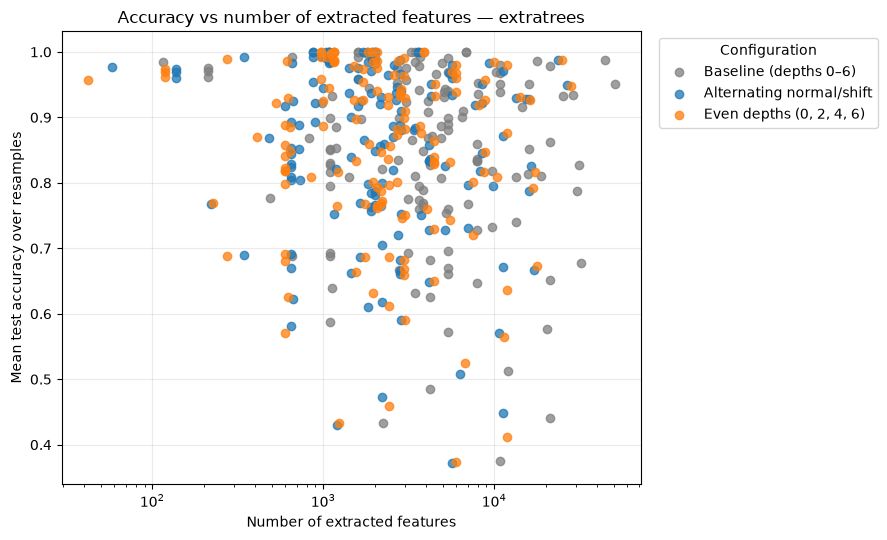

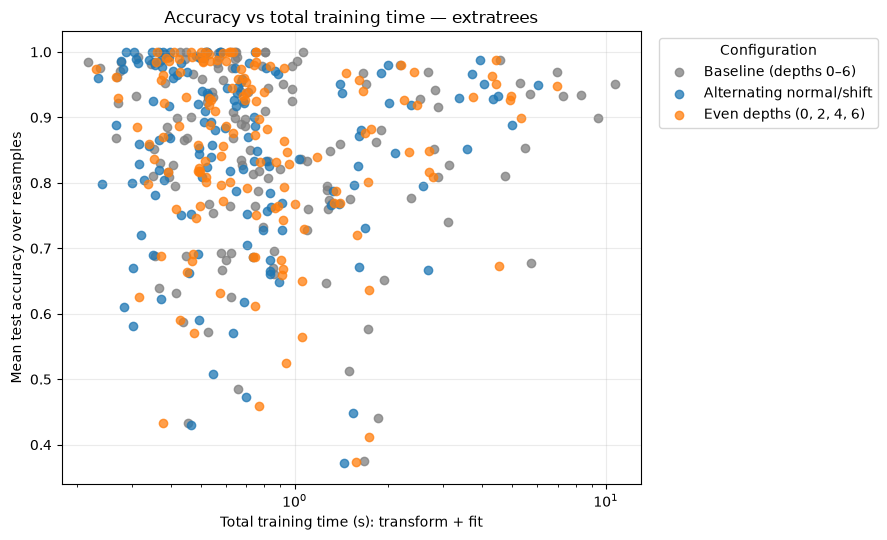

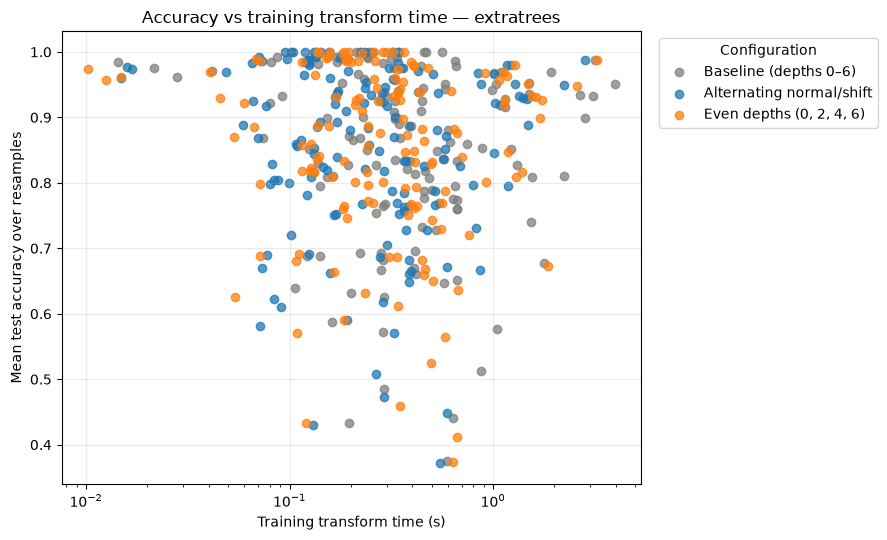

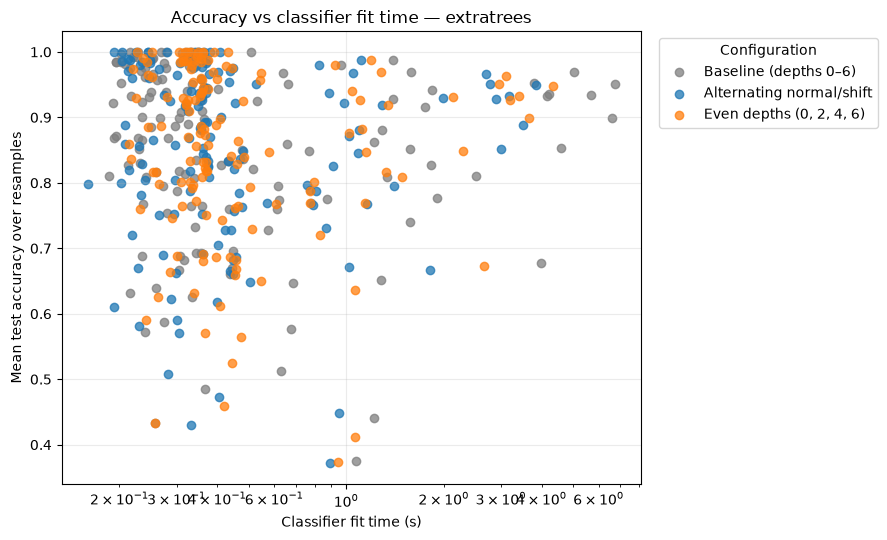

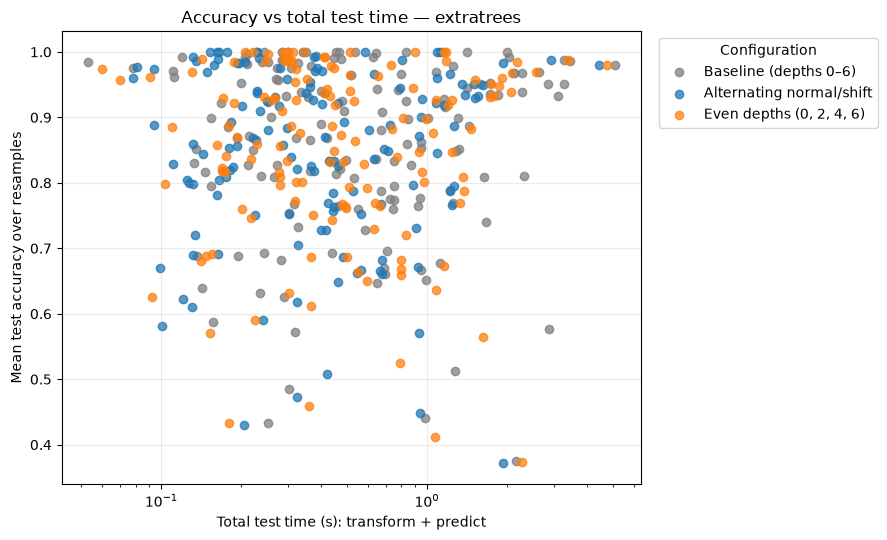

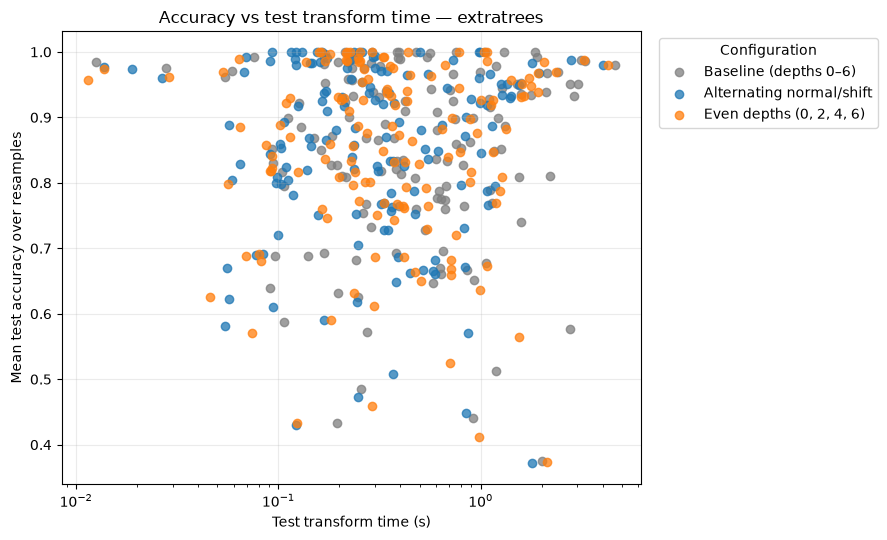

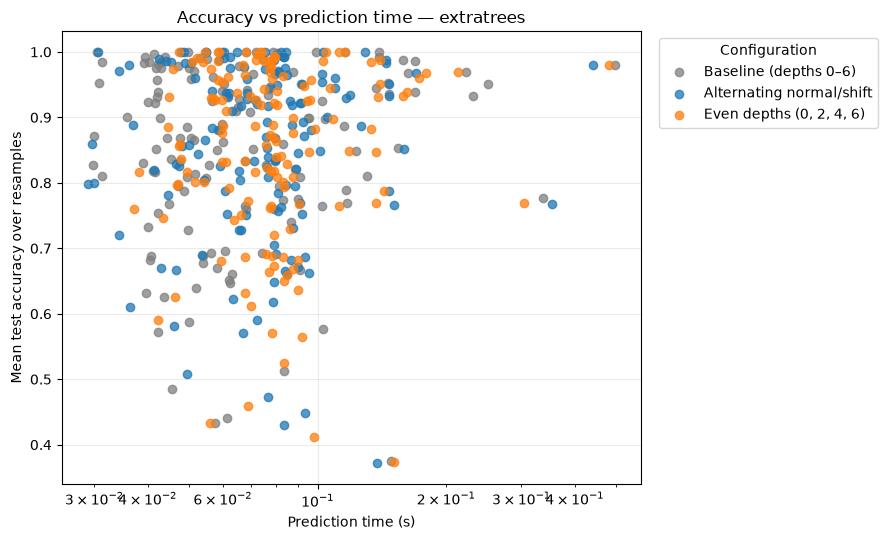

In [11]:
SCATTER_X = {
    "n_features": "Number of extracted features",
    "time_train_total": "Total training time (s): transform + fit",
    "time_transform_train": "Training transform time (s)",
    "time_fit": "Classifier fit time (s)",
    "time_test_total": "Total test time (s): transform + predict",
    "time_transform_test": "Test transform time (s)",
    "time_predict": "Prediction time (s)",
}
configs_in_order = [BASELINE] + COMPARE_CONFIGS

for clf in classifiers:
    data = table[table["classifier"] == clf]
    for x_col, x_label in SCATTER_X.items():
        fig, ax = plt.subplots(figsize=(9, 5.5))
        for config in configs_in_order:
            g = data[data["configuration"] == config].dropna(subset=[x_col, "accuracy"])
            ax.scatter(g[x_col], g["accuracy"], s=36, alpha=0.75, color=CONFIG_COLORS[config], label=config)
        if (data[x_col].dropna() > 0).all():
            ax.set_xscale("log")
        ax.set(xlabel=x_label, ylabel="Mean test accuracy over resamples",
               title=f"Accuracy vs {x_label.split(' (')[0].lower()} — {clf}")
        ax.grid(alpha=0.25)
        ax.legend(title="Configuration", bbox_to_anchor=(1.02, 1), loc="upper left")
        fig.tight_layout()
        plt.show()

## 8. Accuracy distribution across datasets

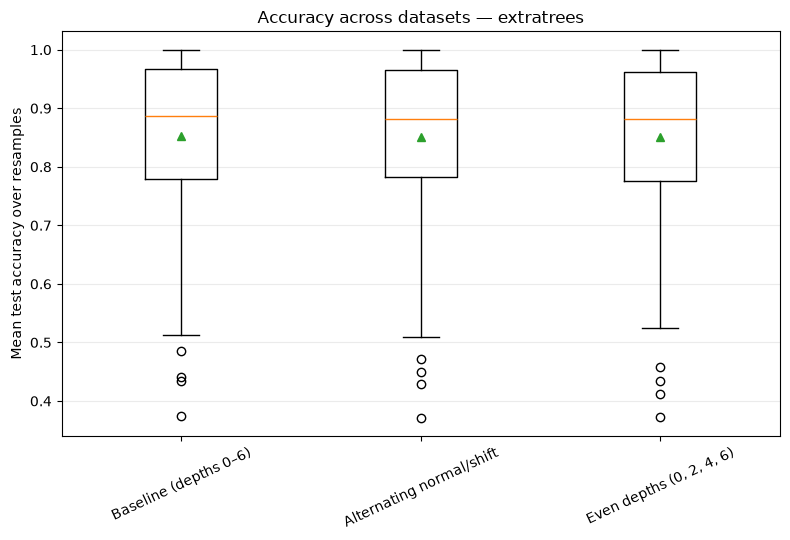

In [12]:
for clf in classifiers:
    data = table[table["classifier"] == clf]
    values = [data.loc[data["configuration"] == c, "accuracy"].dropna().to_numpy() for c in configs_in_order]
    fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(configs_in_order)), 5.5))
    ax.boxplot(values, tick_labels=configs_in_order, showmeans=True)
    ax.set(ylabel="Mean test accuracy over resamples", title=f"Accuracy across datasets — {clf}")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()

## 9. Per-dataset changes versus the baseline, by size group

One figure per metric, one panel per size group, datasets ordered from smallest to largest within each panel. The dashed line is "no change from baseline"; for every metric a bar **above** the line is better than the baseline.
The baseline is not drawn because it is zero by definition. Relative error reduction leaves an empty slot for datasets where the baseline is already perfect (undefined). Plain error difference is omitted since it is just the negative of the accuracy difference.

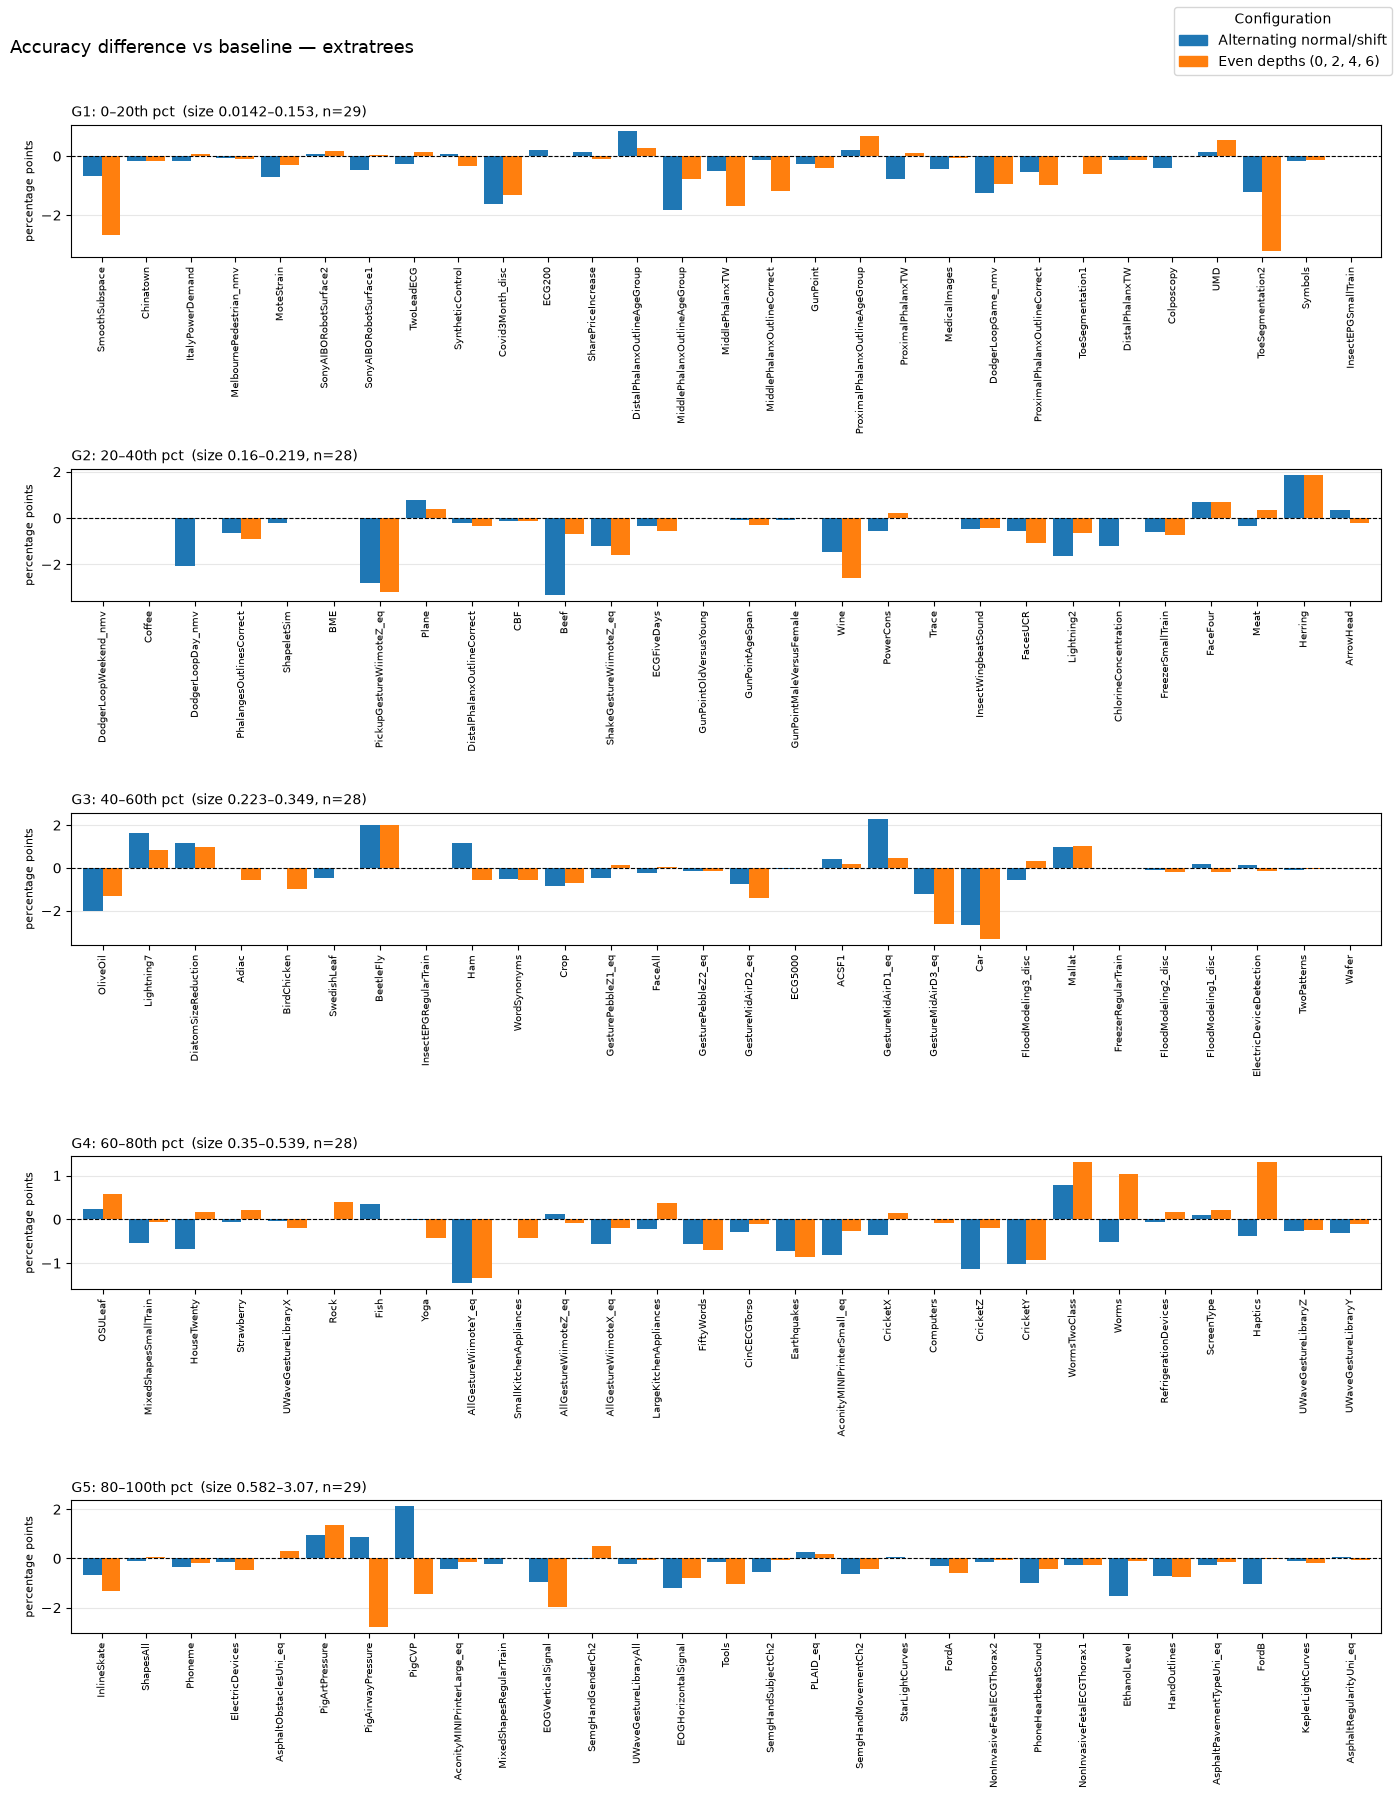

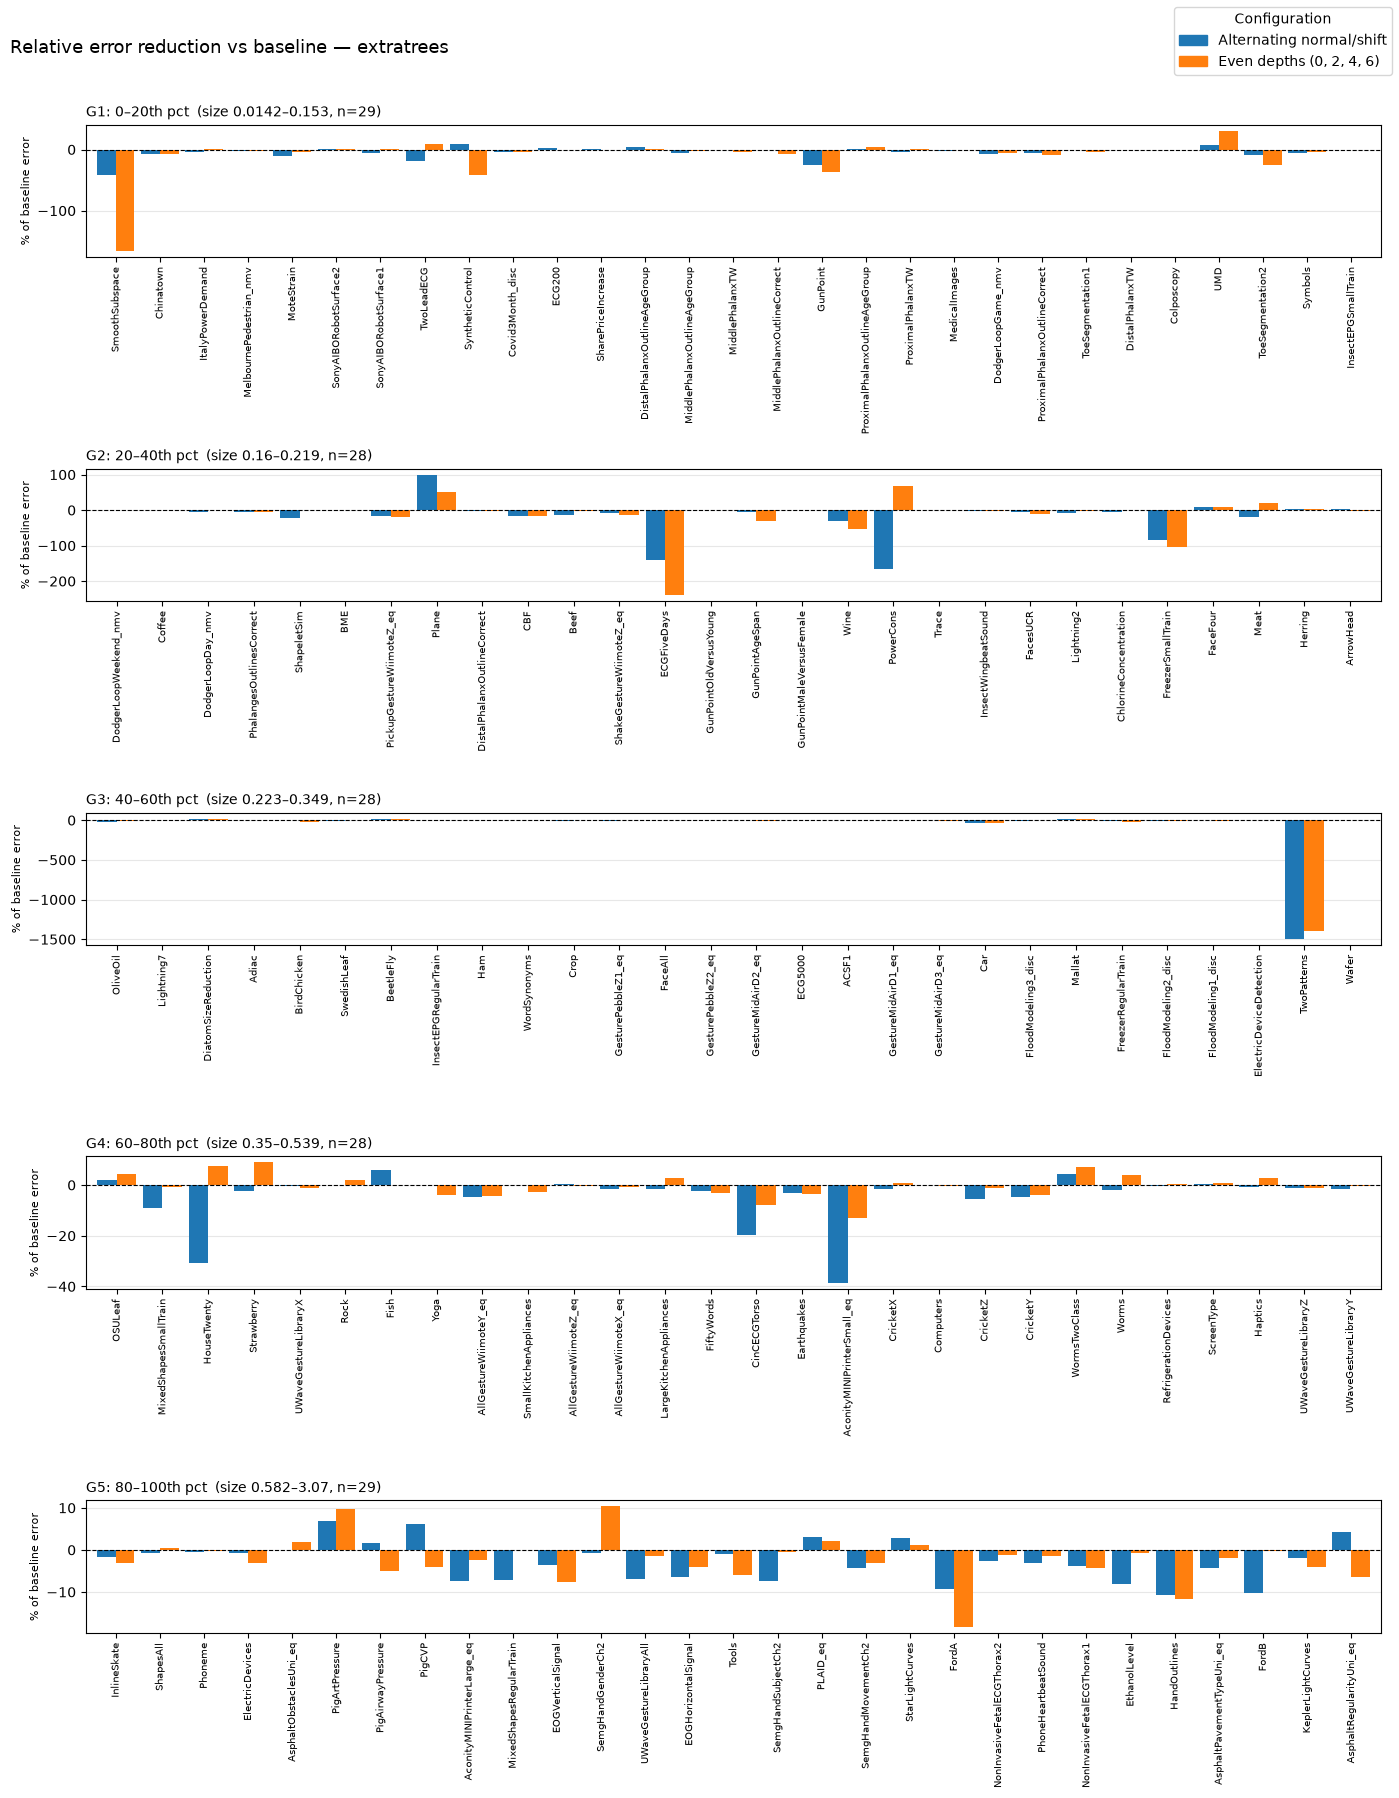

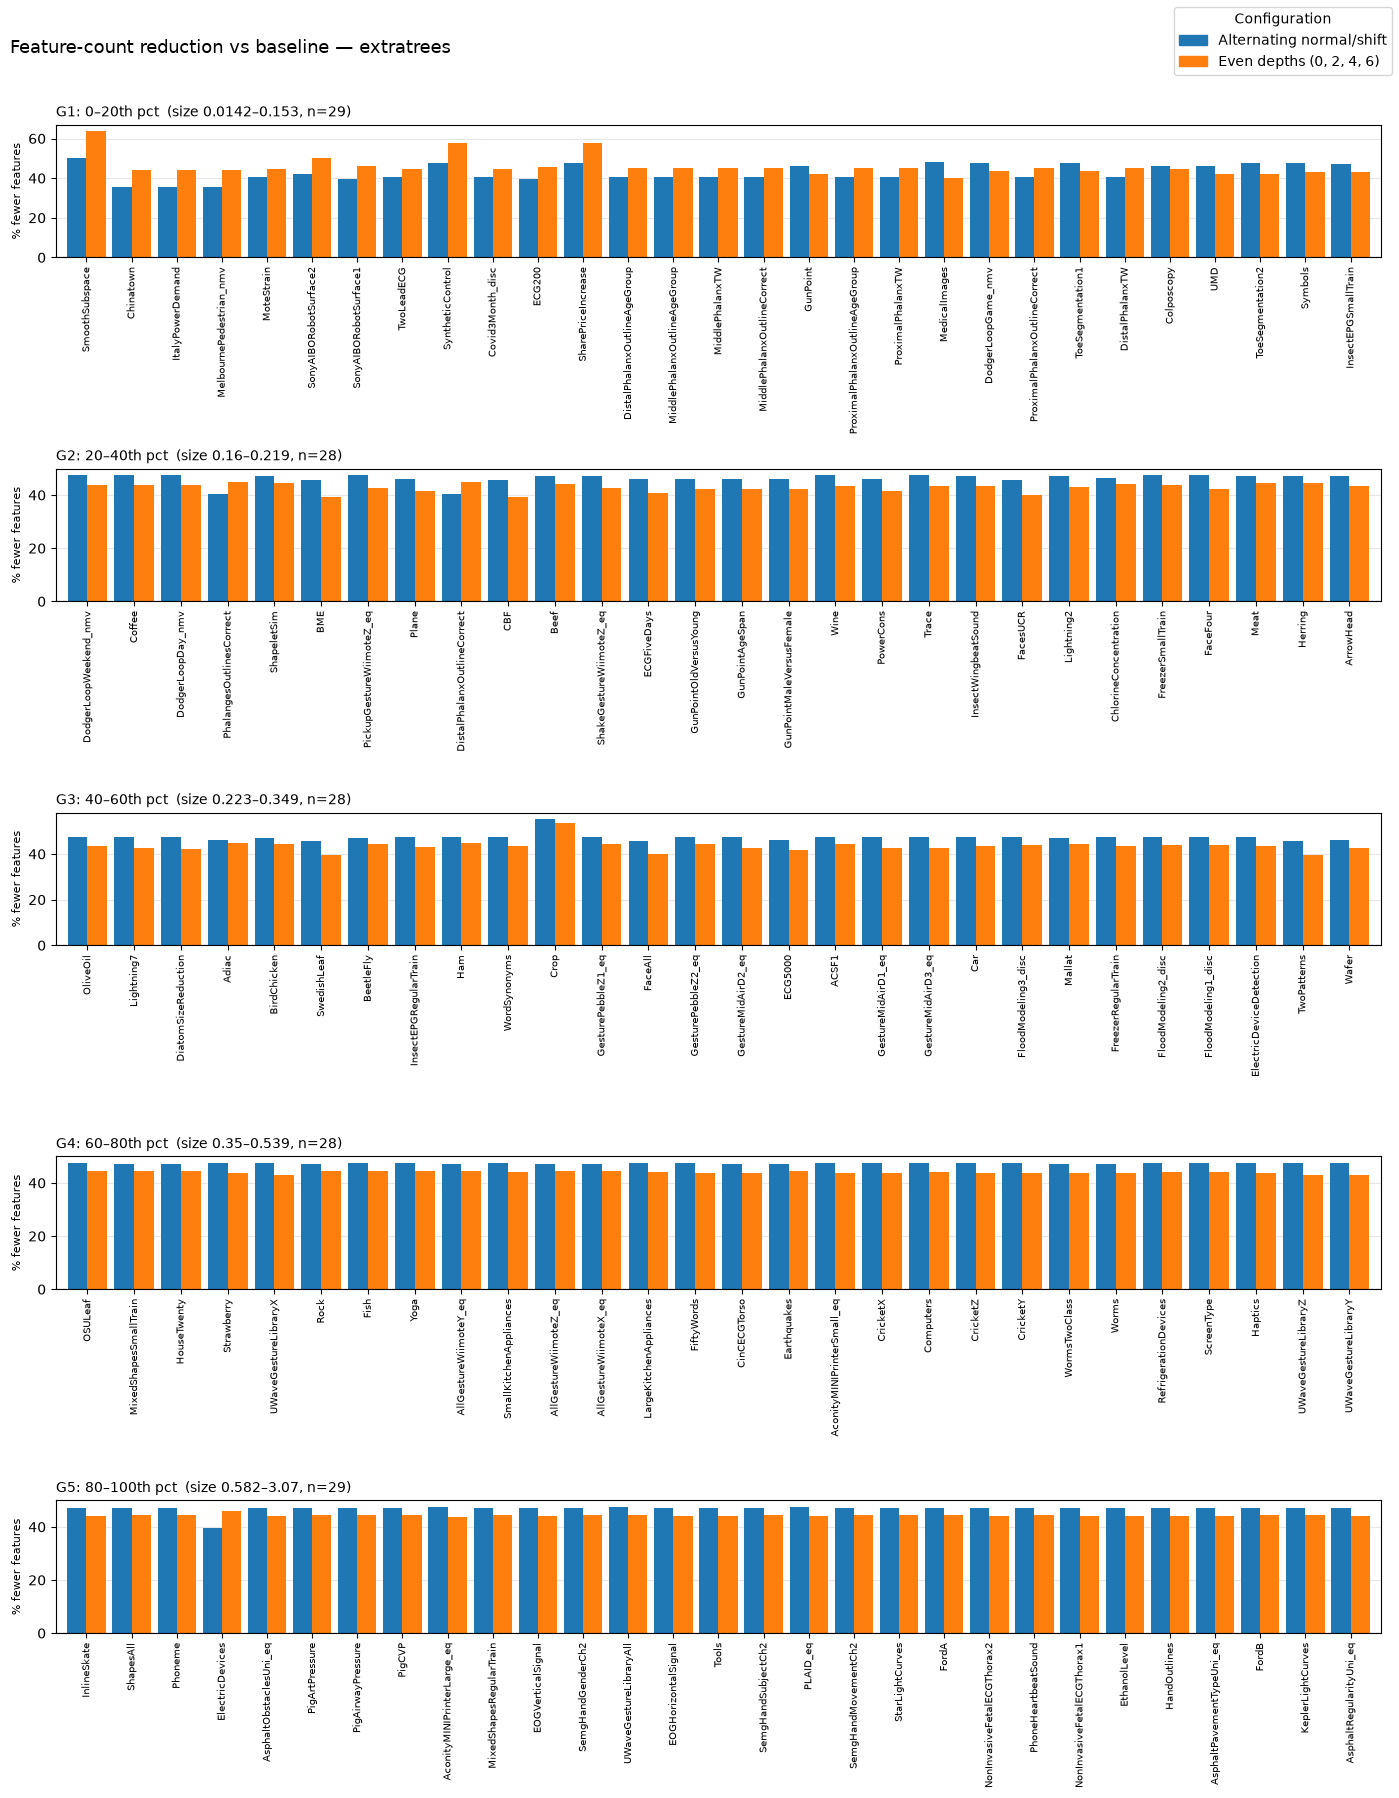

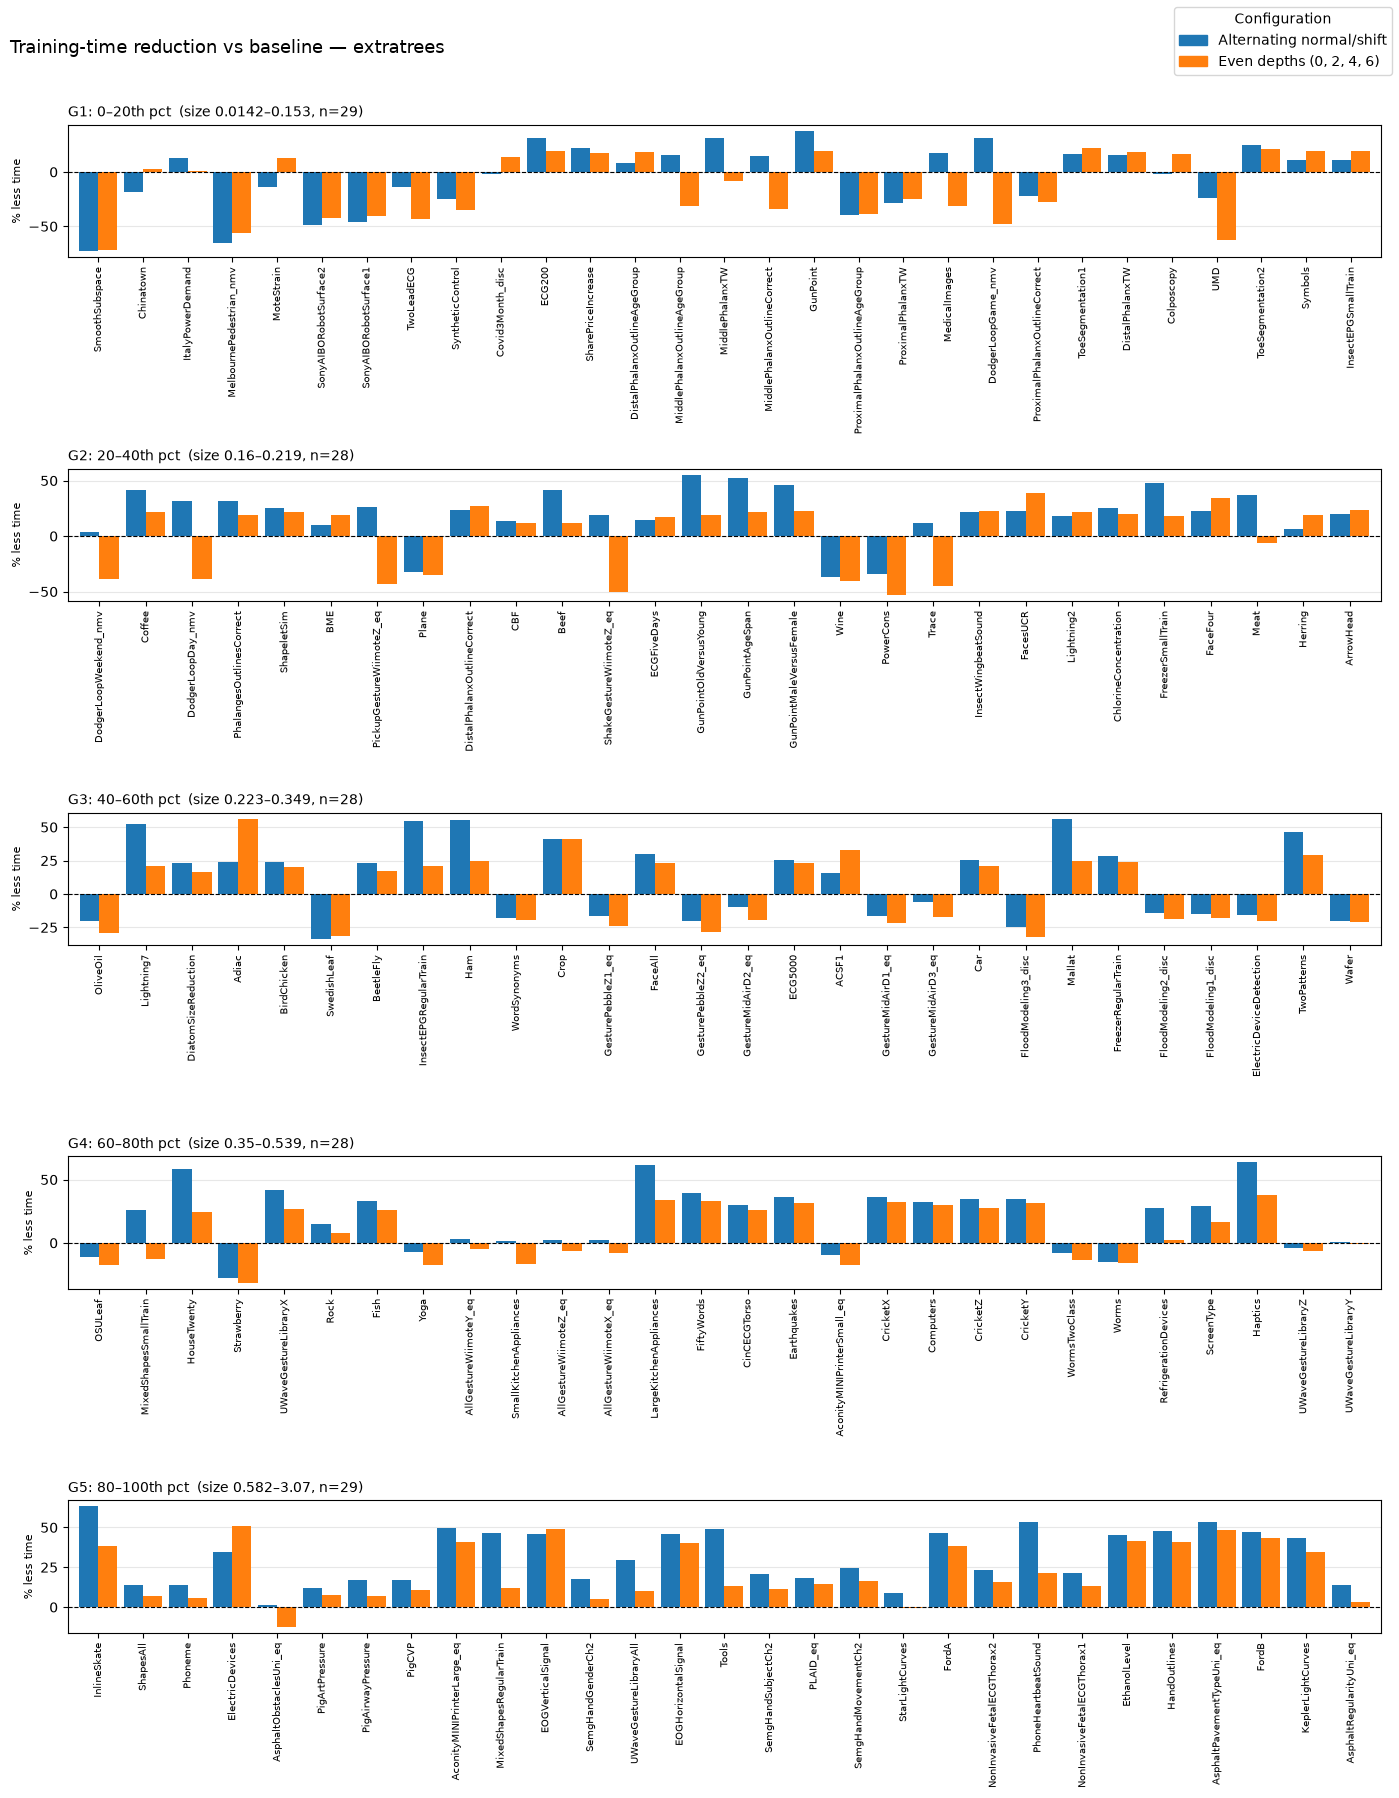

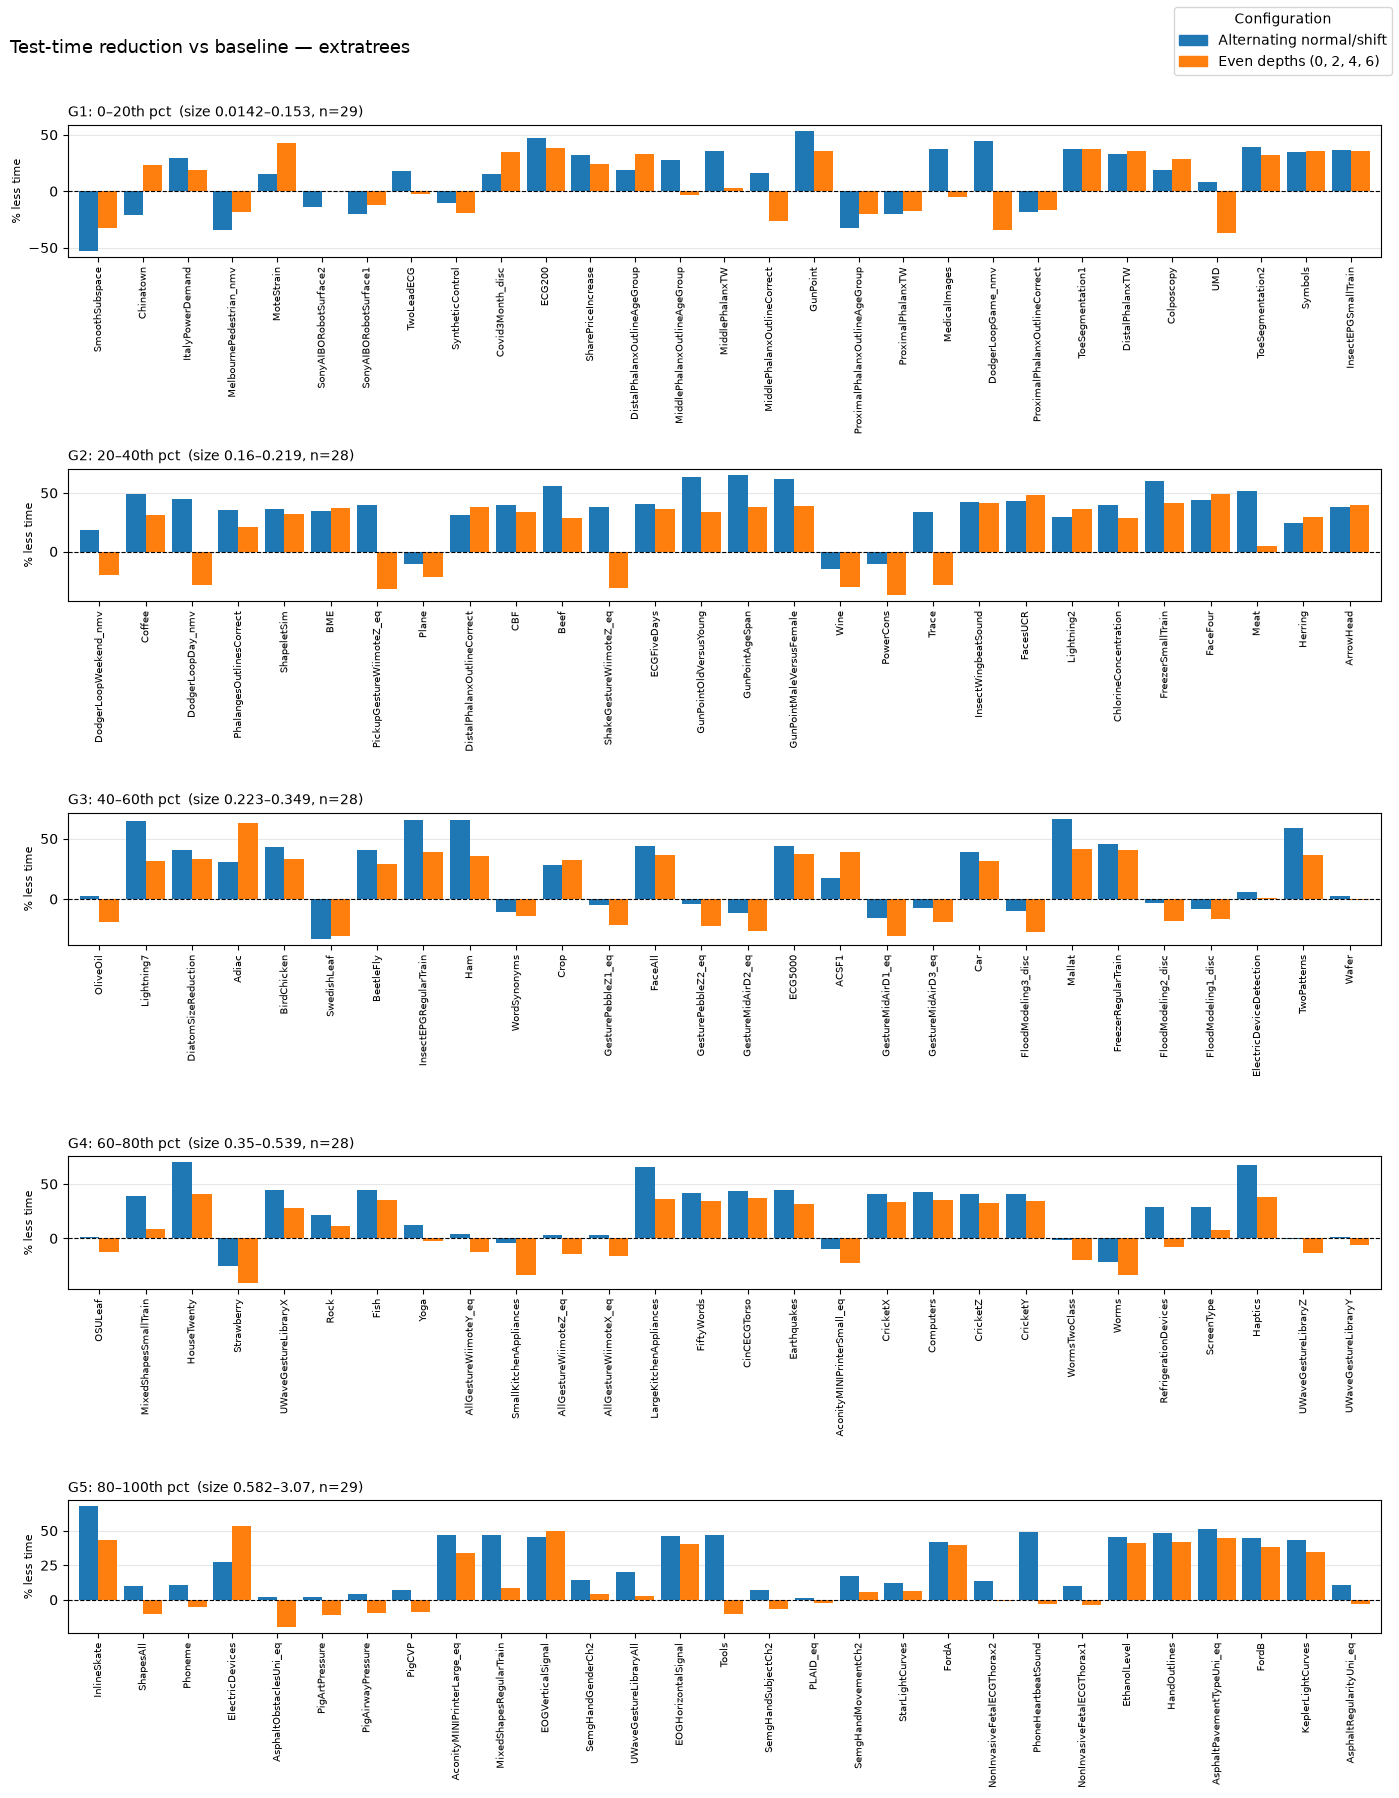

In [13]:
BAR_METRICS = {
    "acc_diff_pp": ("Accuracy difference vs baseline", "percentage points"),
    "error_reduction_pct": ("Relative error reduction vs baseline", "% of baseline error"),
    "feature_reduction_pct": ("Feature-count reduction vs baseline", "% fewer features"),
    "train_time_reduction_pct": ("Training-time reduction vs baseline", "% less time"),
    "test_time_reduction_pct": ("Test-time reduction vs baseline", "% less time"),
}

def plot_grouped_bars(metric, title, ylabel):
    for clf in classifiers:
        sub = cmp[cmp["classifier"] == clf]
        fig, axes = plt.subplots(N_SIZE_GROUPS, 1, figsize=(14, 3.6 * N_SIZE_GROUPS), squeeze=False)
        for ax, group_name in zip(axes[:, 0], GROUP_ORDER):
            g = sub[sub["size_group"] == group_name]
            if g.empty:
                ax.set_visible(False)
                continue
            wide = g.pivot(index="dataset", columns="configuration", values=metric)
            wide = wide.loc[dataset_size.reindex(wide.index).sort_values().index, COMPARE_CONFIGS]
            wide.plot.bar(ax=ax, width=0.85, legend=False, color=[CONFIG_COLORS[c] for c in COMPARE_CONFIGS])
            ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
            ax.set_title(group_name, loc="left", fontsize=10)
            ax.set_xlabel("")
            ax.set_ylabel(ylabel, fontsize=8)
            ax.tick_params(axis="x", labelsize=7, rotation=90)
            ax.grid(axis="y", alpha=0.3)
            ax.set_axisbelow(True)
        fig.legend(handles=[Patch(color=CONFIG_COLORS[c], label=c) for c in COMPARE_CONFIGS],
                   title="Configuration", loc="upper right")
        fig.suptitle(f"{title} — {clf}", x=0.01, ha="left", fontsize=13)
        fig.tight_layout(rect=(0, 0, 1, 0.97))
        plt.show()

for metric, (title, ylabel) in BAR_METRICS.items():
    plot_grouped_bars(metric, title, ylabel)

# Analysis and conclusion of results

Based on these results, taking normal intervals from every second row and shfit features from every other second row (alternating normal/shift) is the only method truely considerable as an improvement.

Experiments with depths 0 and 1 removed both severly reduced accuracy, with little reduction in training time of feature count, indicating that earlier layers are relevant for classification. Theoretically, these layers (especially layer 0) provide approximate summary statistics for the dataset as a whole, which are highly relevant for classification. The performance drops in initial tests with these configurations yielded poor results, so further tests werent conducted.

Taking statistics for every second depth appeared benificial in early tests, although still underperforming compared to alternating depths. For this reason, further experiments with this method were conducted. Although this method dropped the feature count by an average of 44% compared to the baseline (with all the original depths taken), it lead to a mean accuracy loss of 0.376%, with an only 4% average reduction in training time. This increase in training time may have been attributable to the reduction in features creating a harder problem for the classifier, making training time reductions minimal despite the large reduction in features.

The most promising of these experiments was the alternating normal/shift. Although this method did result in a mean accuracy decrease of 0.228%, this method produced 46.2% less features and a training time reduction of 15.2%. Generally, this method appeared to give the best performance increase, in the form of training time reduction, in larger datasets, performance benefits dropping as dataset size dropped. 

This method produced a mean relative error increase of 17.2%. This increase was primarily due to 1 outlying result from a dataset in the 40 - 60th percentile by dataset size, called Twopatterns, which had a relative error increase of ~ 1300%, roughly 6 times greater increase than the next worst dataset. This was a result of the fact that the error of the original model for this dataset was negligable, ~0%. The atlernating normal/shift still achieved an average error only 0.08% on this dataset. Based on this result, it is clear that relative error has the potential to severly alter the apparent performance of models, which is why it was no used in the final analysis.